# Load plot and analyze phase sweep results

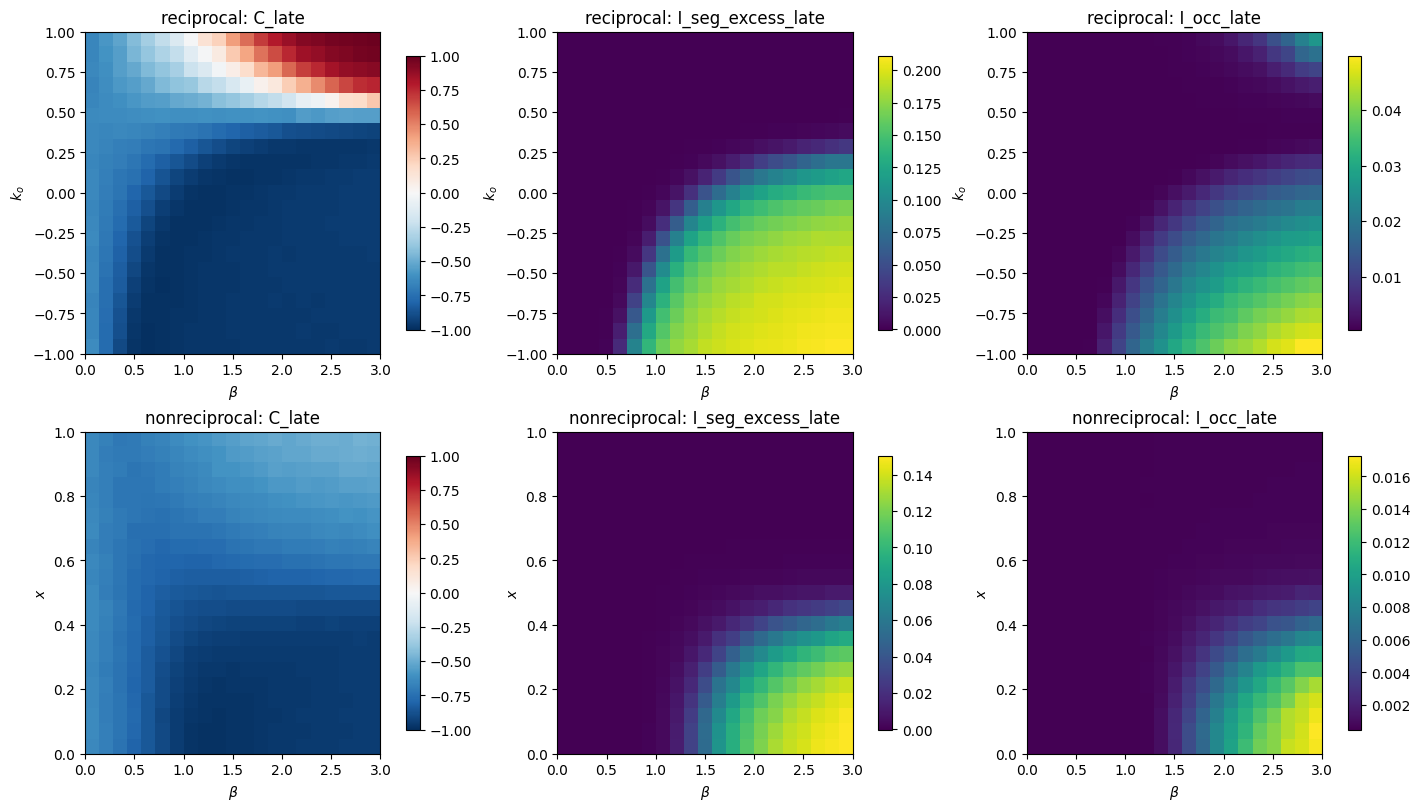

In [7]:
import argparse
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


# p=argparse.ArgumentParser(description=__doc__)
# p.add_argument('--out',type=Path,default=Path('schelling_phase_sweep'))
# p.add_argument('--keys',nargs='+',default=['C_late','I_seg_excess_late','I_occ_late'])
# p.add_argument('--save',type=Path,default=None)
# a=p.parse_args()
out = Path('../phase_sweep')
keys = ['C_late','I_seg_excess_late','I_occ_late']
save = None #Path("../images/phase_sweep")

families=['reciprocal','nonreciprocal']
found=[]
for fam in families:
    path= out/f'{fam}_grids.npz'
    if path.exists(): found.append((fam,path))
if not found: p.error('No *_grids.npz files found; finish a sweep or run --aggregate-only')

fig,axes=plt.subplots(len(found),len(keys),figsize=(4.7*len(keys),4*len(found)),
                      squeeze=False,constrained_layout=True)
for ir,(family,path) in enumerate(found):
    with np.load(path,allow_pickle=False) as z:
        xs=z['x']; bs=z['beta']
        for ic,key in enumerate(keys):
            ax=axes[ir,ic]
            if key not in z:
                ax.text(.5,.5,f'{key}\nmissing',ha='center',va='center',transform=ax.transAxes)
                continue
            values=z[key]
            image=np.ma.masked_invalid(values)
            kwargs=dict(origin='lower',aspect='auto',interpolation='nearest',
                        extent=[bs[0],bs[-1],xs[0],xs[-1]])
            if key=='C_late': kwargs.update(cmap='RdBu_r',vmin=-1,vmax=1)
            else: kwargs.update(cmap='viridis')
            im=ax.imshow(image.T,**kwargs)
            ax.set_title(f'{family}: {key}')
            ax.set_ylabel('$k_o$' if family=='reciprocal' else '$x$')
            ax.set_xlabel(r'$\beta$')
            fig.colorbar(im,ax=ax,shrink=.85)
if save:
    save.parent.mkdir(parents=True,exist_ok=True)
    fig.savefig(a.save,dpi=180)
    print('Saved',a.save)
else:plt.show()

In [9]:
data = np.load(path,allow_pickle=False)

In [12]:
for k in data.keys():
    print(k)

beta
x
mean_A_late
mean_B_late
mean_n_late
mean_m_late
mean_vacancy_late
total_A_late
total_B_late
total_vacancy_late
variance_A_late
variance_B_late
variance_n_late
variance_m_late
variance_vacancy_late
std_n_late
std_m_late
std_vacancy_late
I_seg_late
I_seg_excess_late
I_occ_late
I_occ_excess_late
P_plus_late
P_minus_late
C_late
dissimilarity_late
entropy_kl_late
local_shannon_entropy_late
normalized_entropy_segregation_late
legacy_dissimilarity_late
legacy_mean_relative_entropy_late
C_valid_fraction
min_species
min_vacancy
max_mass_drift
n_schelling_noise_limited_faces
k_peak_plus
k_peak_minus


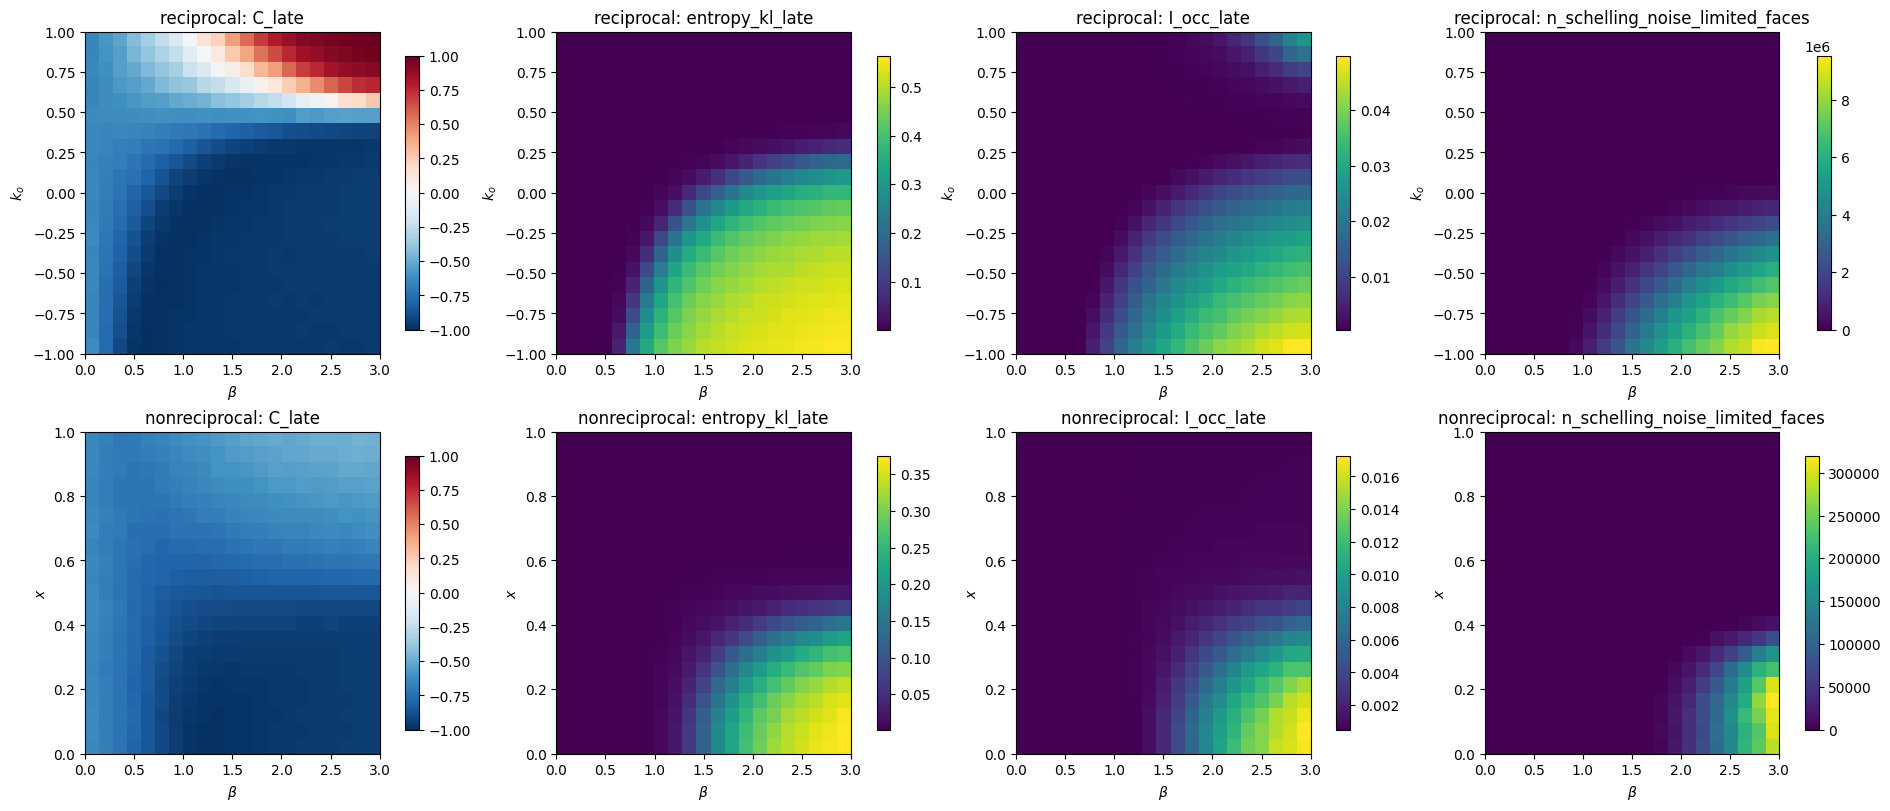

In [8]:
import argparse
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


# p=argparse.ArgumentParser(description=__doc__)
# p.add_argument('--out',type=Path,default=Path('schelling_phase_sweep'))
# p.add_argument('--keys',nargs='+',default=['C_late','I_seg_excess_late','I_occ_late'])
# p.add_argument('--save',type=Path,default=None)
# a=p.parse_args()
out = Path('../phase_sweep')
keys = ['C_late', "entropy_kl_late",
    "I_occ_late","n_schelling_noise_limited_faces"] #"k_peak_plus", "k_peak_minus"]
save = None #Path("../images/phase_sweep")

families=['reciprocal','nonreciprocal']
found=[]
for fam in families:
    path= out/f'{fam}_grids.npz'
    if path.exists(): found.append((fam,path))
if not found: p.error('No *_grids.npz files found; finish a sweep or run --aggregate-only')

fig,axes=plt.subplots(len(found),len(keys),figsize=(4.7*len(keys),4*len(found)),
                      squeeze=False,constrained_layout=True)
for ir,(family,path) in enumerate(found):
    with np.load(path,allow_pickle=False) as z:
        xs=z['x']; bs=z['beta']
        for ic,key in enumerate(keys):
            ax=axes[ir,ic]
            if key not in z:
                ax.text(.5,.5,f'{key}\nmissing',ha='center',va='center',transform=ax.transAxes)
                continue
            values=z[key]
            image=np.ma.masked_invalid(values)
            kwargs=dict(origin='lower',aspect='auto',interpolation='nearest',
                        extent=[bs[0],bs[-1],xs[0],xs[-1]])
            if key=='C_late': kwargs.update(cmap='RdBu_r',vmin=-1,vmax=1)
            else: kwargs.update(cmap='viridis')
            im=ax.imshow(image.T,**kwargs)
            ax.set_title(f'{family}: {key}')
            ax.set_ylabel('$k_o$' if family=='reciprocal' else '$x$')
            ax.set_xlabel(r'$\beta$')
            fig.colorbar(im,ax=ax,shrink=.85)
if save:
    save.parent.mkdir(parents=True,exist_ok=True)
    fig.savefig(a.save,dpi=180)
    print('Saved',a.save)
else:plt.show()

In [38]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

# Find repository root
ROOT = Path.cwd().resolve()
if not (ROOT / "scripts").is_dir():
    ROOT = ROOT.parent

# Make scripts/ importable
sys.path.insert(0, str(ROOT / "scripts"))

# Automatically reload modules when their source code changes
%load_ext autoreload
%autoreload 2

import plot_schelling_phase_diagram as psd

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Theory overlay: sigma=0.5, rho=(0.35, 0.35), D=(1.0, 1.0), N=(128, 128), L=(50.0, 50.0), bc=Neumann
reciprocal: stable fraction on theory grid=0.287; margin range -0.3275..0.1304
nonreciprocal: stable fraction on theory grid=0.577; margin range -0.1212..0.1304


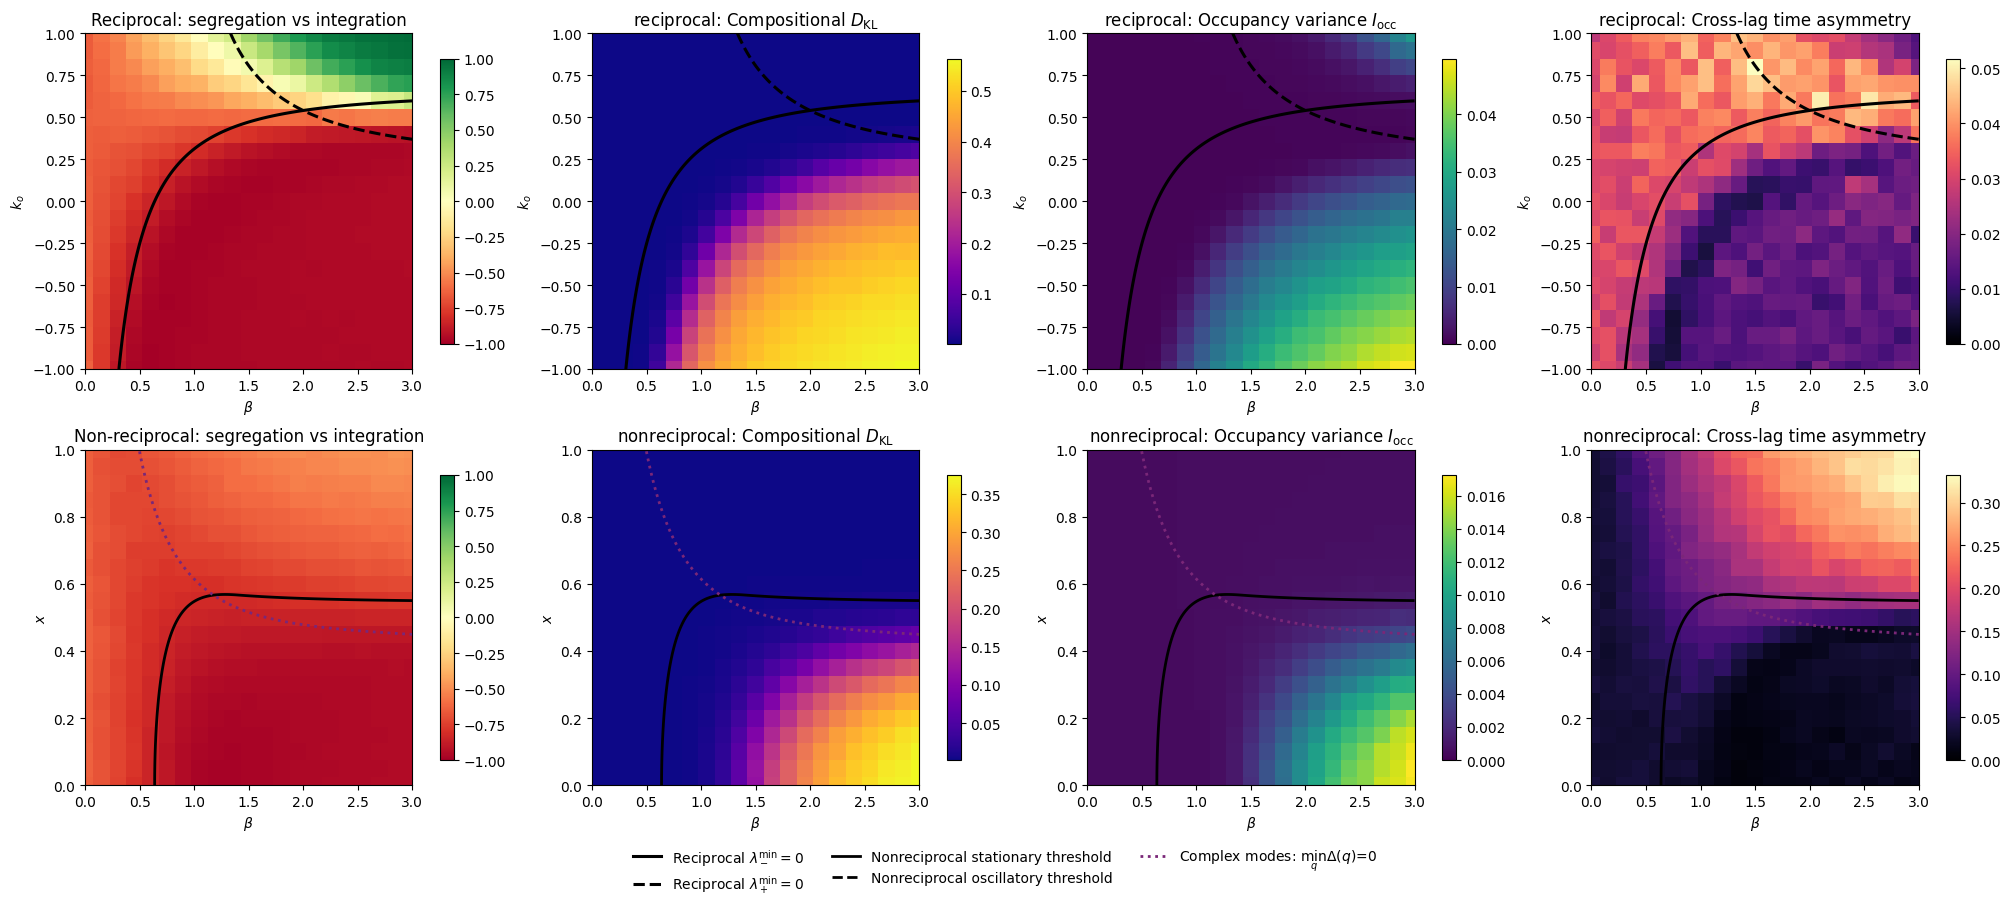

In [9]:
fig, axes = psd.main([
    "--out", str(ROOT / "phase_sweep"),
    # "--longwave",
    "--keys",
    "C_late",
    "entropy_kl_late",
    "I_occ_late",
    "temporal_antisymmetry",
    # "oscillation_peak",
])

# Customize after generating the plots
fig.set_size_inches(20, 9)

axes[0, 0].set_title("Reciprocal: segregation vs integration")
axes[1, 0].set_title("Non-reciprocal: segregation vs integration")
plt.show()
# display(fig)

## Plot configurations and observables for a run

reciprocal: beta=1.200, x=-0.700


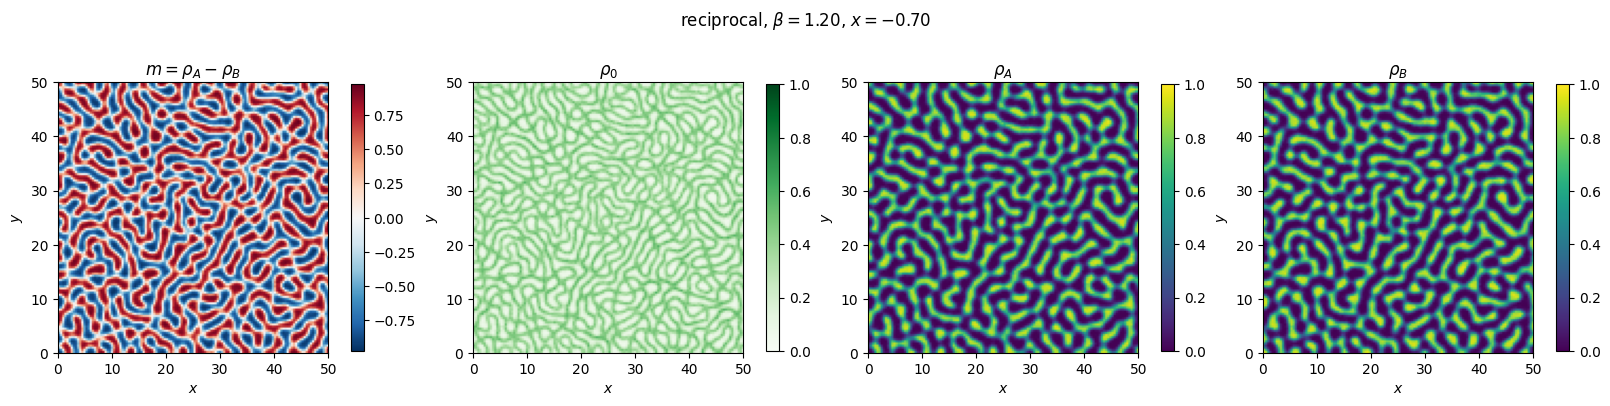

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Select parameters
family = "reciprocal"   # or "nonreciprocal"
x = -0.6666
beta = 1.2
replica = 0

folder = ROOT / "phase_sweep"

# Find nearest simulated parameter values
with np.load(folder / f"{family}_grids.npz") as grid:
    ib = np.argmin(abs(grid["beta"] - beta))
    ix = np.argmin(abs(grid["x"] - x))
    beta_actual = grid["beta"][ib]
    x_actual = grid["x"][ix]

# Load simulation
file = folder / family / f"b{ib:02d}_x{ix:02d}_r{replica:02d}.npz"

with np.load(file) as data:
    phi = data["snapshots"][:, -1]  # final snapshot, (2, Nx, Ny)
    Lx, Ly = data["L"]

print(f"{family}: beta={beta_actual:.3f}, x={x_actual:.3f}")

# Construct collective fields
rho_A, rho_B = phi
rho_0 = 1 - (rho_A + rho_B)
m = rho_A - rho_B

# Plot
fig, axes = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)

fields = [m, rho_0, rho_A, rho_B]
titles = [r"$m=\rho_A-\rho_B$",
          r"$\rho_0$", r"$\rho_A$", r"$\rho_B$", ]
cmaps = ["RdBu_r", "Greens",  "viridis", "viridis", ]

for ax, field, title, cmap in zip(axes, fields, titles, cmaps):
    vmax = max(abs(field.min()), abs(field.max())) if title.startswith("$m=") else 1
    im = ax.imshow(
        field.T, origin="lower",
        extent=[0, Lx, 0, Ly],
        cmap=cmap,
        vmin=-vmax if title.startswith("$m=") else 0,
        vmax=vmax,
    )
    ax.set_title(title)
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_aspect("equal")
    fig.colorbar(im, ax=ax, shrink=0.75)

fig.suptitle(rf"{family}, $\beta={beta_actual:.2f}$, $x={x_actual:.2f}$")
plt.show()

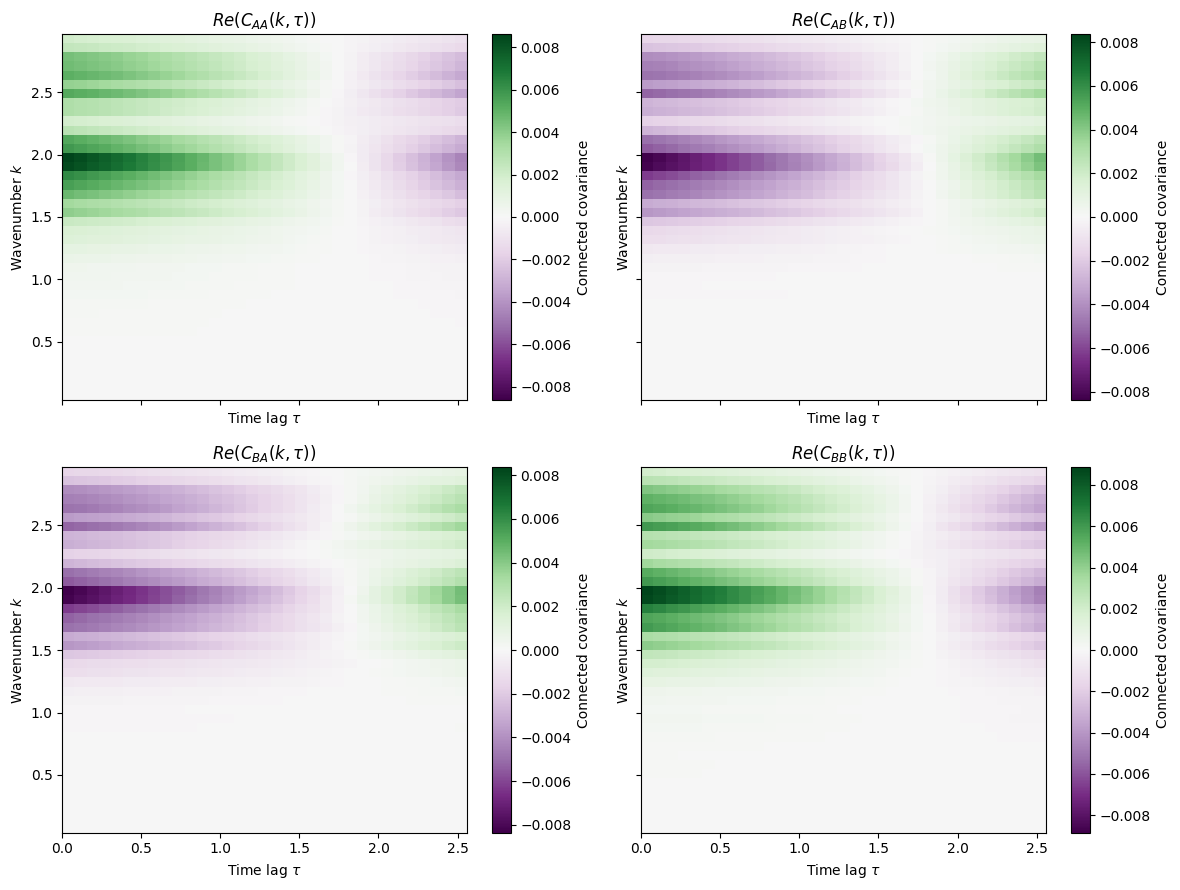

In [36]:
with np.load(file) as data:
    tau = data["tau"]
    k = data["k_dynamic"]
    C = data["C_k_tau"]  # shape: (n_lags, n_k_bins, 2, 2)

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)

for a in range(2):
    for b in range(2):
        ax = axes[a, b]

        # Real part of connected covariance, shape (n_k_bins, n_lags)
        data = np.real(C[:, :, a, b]).T

        vmax = np.max(np.abs(data))
        im = ax.imshow(
            data,
            origin="lower",
            aspect="auto",
            extent=[tau[0], tau[-1], k[0], k[-1]],
            cmap="PRGn",
            vmin=-vmax,
            vmax=vmax,
            interpolation="nearest",
        )

        ax.set_title(rf"$Re(C_{{{'AB'[a]}{'AB'[b]}}}(k,\tau))$")
        ax.set_xlabel(r"Time lag $\tau$")
        ax.set_ylabel(r"Wavenumber $k$")
        fig.colorbar(im, ax=ax, label="Connected covariance")

plt.tight_layout()
plt.show()

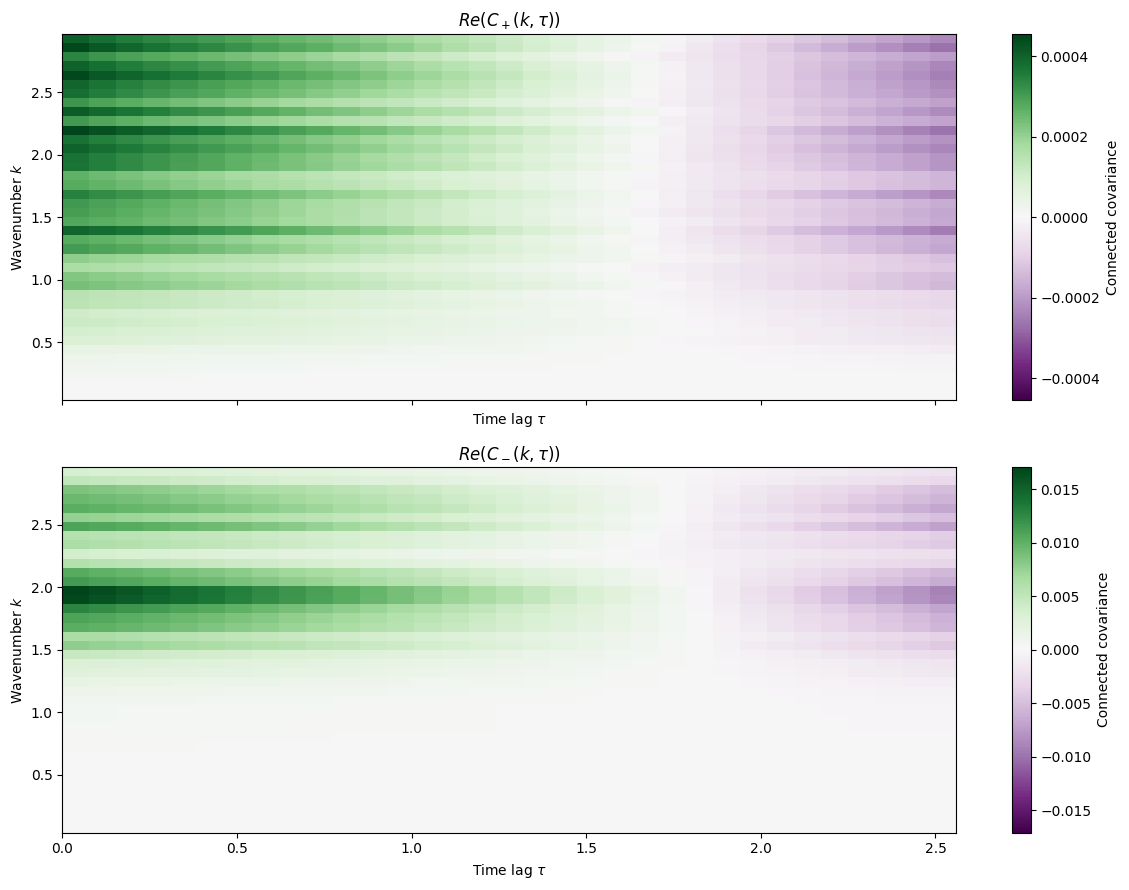

In [37]:
C_plus  = (C[:, :, 0, 0] + C[:, :, 1, 1]
           + C[:, :, 0, 1] + C[:, :, 1, 0]) / 2

C_minus = (C[:, :, 0, 0] + C[:, :, 1, 1]
           - C[:, :, 0, 1] - C[:, :, 1, 0]) / 2

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True, sharey=True)

for a in range(2):
    ax = axes[a]

    # Real part of connected covariance, shape (n_k_bins, n_lags)
    data = np.real(C_plus).T if a == 0 else np.real(C_minus).T

    vmax = np.max(np.abs(data))
    im = ax.imshow(
        data,
        origin="lower",
        aspect="auto",
        extent=[tau[0], tau[-1], k[0], k[-1]],
        cmap="PRGn",
        vmin=-vmax,
        vmax=vmax,
        interpolation="nearest",
    )

    ax.set_title(rf"$Re(C_+(k,\tau))$" if a ==0 else rf"$Re(C_-(k,\tau))$" )
    ax.set_xlabel(r"Time lag $\tau$")
    ax.set_ylabel(r"Wavenumber $k$")
    fig.colorbar(im, ax=ax, label="Connected covariance")

plt.tight_layout()
plt.show()

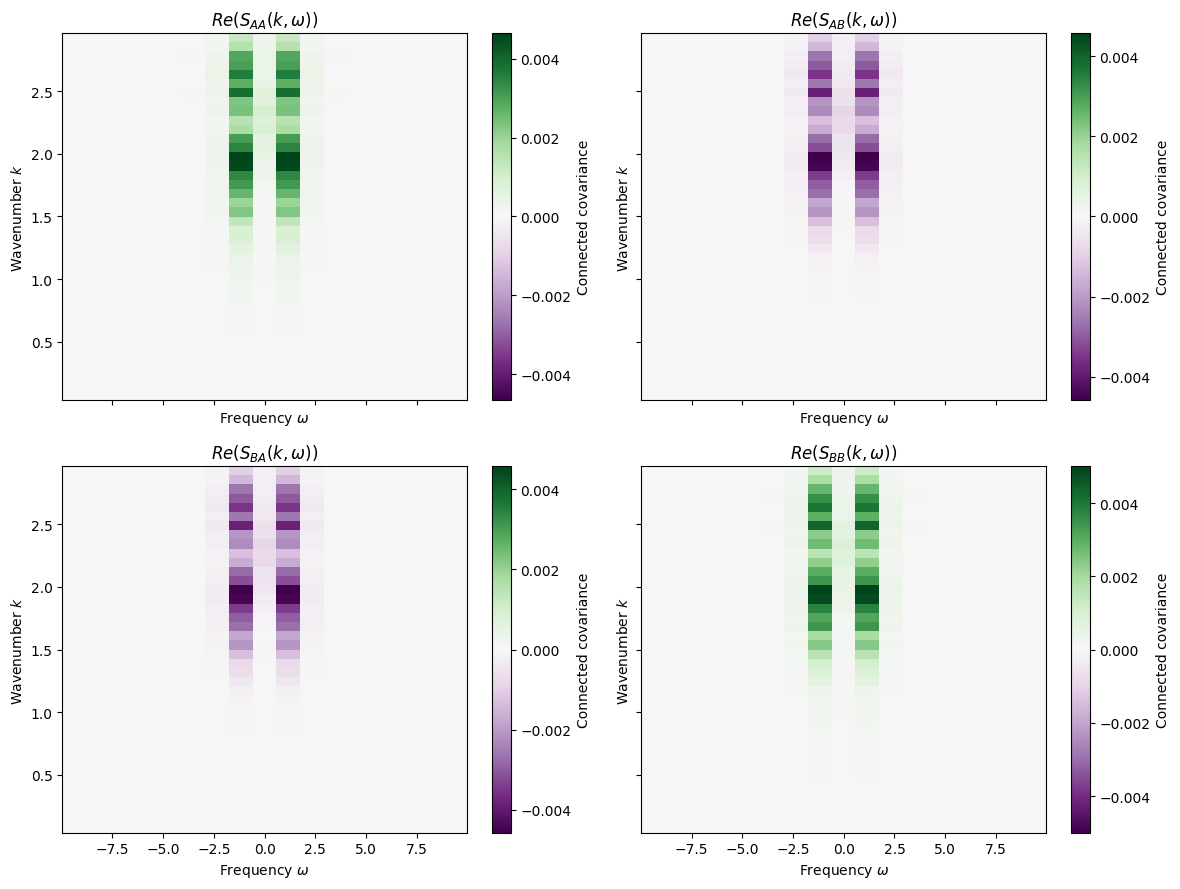

In [35]:
with np.load(file) as data:
    omega = data["omega"]
    k = data["k_dynamic"]
    S_k_omega = data["S_k_omega"] 

om_thsld = 10
om_mask = (omega > -om_thsld) & (omega<om_thsld)
omega_range = omega[om_mask]
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)

for a in range(2):
    for b in range(2):
        ax = axes[a, b]

        data = np.real(S_k_omega[:, om_mask, a, b])

        vmax = np.max(np.abs(data))
        im = ax.imshow(
            data,
            origin="lower",
            aspect="auto",
            extent=[omega_range[0], omega_range[-1], k[0], k[-1]],
            cmap="PRGn",
            vmin=-vmax,
            vmax=vmax,
            interpolation="nearest",
        )

        ax.set_title(rf"$Re(S_{{{'AB'[a]}{'AB'[b]}}}(k,\omega))$")
        ax.set_xlabel(r"Frequency $\omega$")
        ax.set_ylabel(r"Wavenumber $k$")
        fig.colorbar(im, ax=ax, label="Connected covariance")

plt.tight_layout()
plt.show()

In [11]:
for k in data.keys():
    print(k)

family
beta
x
seed
replicate
kappa
dt
dt_saved
sigma
h
people_per_cell
N
L
rho_bar
nsteps
noise
min_species_full
min_vacancy_full
times
burn_frame
elapsed_seconds
k
k_edges
k_counts
S_dct
S_plus
S_minus
S_reference
S_excess
excess_plus
excess_minus
C_threshold
mean_A
mean_B
mean_n
mean_m
mean_vacancy
total_A
total_B
total_vacancy
variance_A
variance_B
variance_n
variance_m
variance_vacancy
std_n
std_m
std_vacancy
I_seg
I_seg_excess
I_seg_mixing_baseline
I_occ
I_occ_excess
P_plus
P_minus
C
dissimilarity
entropy_kl
local_shannon_entropy
normalized_entropy_segregation
legacy_dissimilarity
legacy_mean_relative_entropy
snapshot_indices
snapshots
dynamic_frame_indices
k_dynamic
tau
C_k_tau
C_plus_tau
C_minus_tau
omega
S_k_omega
S_plus_omega
S_minus_omega
diag_n_calls
diag_n_low_entries
diag_mass_added_low
diag_max_low_violation
diag_n_high_entries
diag_mass_removed_high
diag_max_high_violation
diag_n_simplex_cells
diag_mass_removed_simplex
diag_max_simplex_violation
diag_mass_transferred_low

## Power spectra for selected run

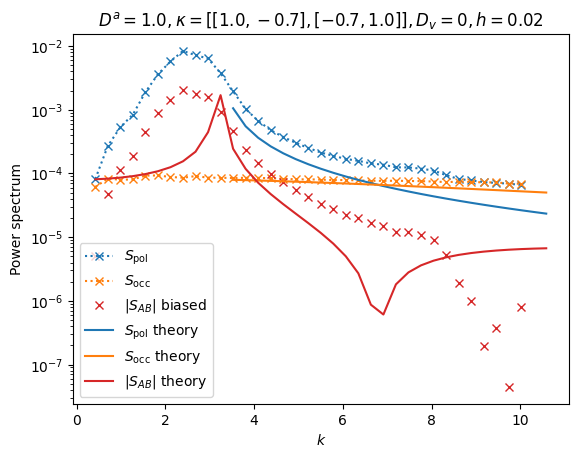

In [69]:
from scipy.interpolate import interp1d
from scipy.optimize import minimize

# Make scripts/ importable
sys.path.insert(0, str(ROOT / "fhd"))

from structure_factor import *
from operations import fit_amplitude_logspace

with np.load(file) as data:
    k_bins = data['k']
    power_spectra = data['S_dct']
    a0, b0 = data['rho_bar']
    # b0 = data['mean_B'].mean()
    dx = data["L"][0]/data["N"][0]
    param = {'beta': data['beta'],
             'kappa': data['kappa'],
             'sigma': data['sigma'],
             'D': np.ones(2),
             'D_v': 0,
             'h': data['h']}
    
# k_bins, power_spectra, G_AB, _ ,_ , _ = fhd.power_spectrum_dct_2d(phi_run[:,:averaging_ep,:,:], sim.L, num_bins= 60, bp = averaging_bp, centered = True, use_lattice_k = True)
# k_bins, P_fr, G_AB_fr, _ ,_ , _ = fhd.power_spectrum_dct_2d(phi_run_fr, sim_2d.L, num_bins= 60, bp = averaging_bp, centered = True, use_lattice_k = True)
# param['h'] = h

averaging_bp = 50
averaging_ep = 100

S_AA_theory = np.zeros(len(k_bins))
S_AB_theory = np.zeros(len(k_bins))
S_BB_theory = np.zeros(len(k_bins))


for i, k in enumerate(k_bins):
    structure_factors = structure_factor(k, a0, b0, param)
    S_AA_theory[i] = structure_factors[0,0]
    S_AB_theory[i] = structure_factors[0,1]
    S_BB_theory[i] = structure_factors[1,1]

S_pol_theory = S_AA_theory + S_BB_theory - 2*S_AB_theory
S_occ_theory = S_AA_theory +S_BB_theory + 2*S_AB_theory

# k_interp = np.linspace(k_bins.min(), k_bins.max(), 1000)  # 1000 points for smooth interpolation
# interpolate_func = interp1d(k_bins, power_spectra[-1,:,0,0], kind='cubic', fill_value="extrapolate")
# SAA_interp = interpolate_func(k_interp)

# # Find the k value where the spectrum is maximal
# k_max_AA = k_interp[np.argmax(SAA_interp)]

# Maximal wavenumber of annular Brillouin zone
K_cut = np.pi / dx  # or min(pi/dx, pi/dy)
mask = k_bins <= K_cut +2

amp = 4000
theory_bp = 9
theory_ep = -2
k_bins_thy = k_bins[mask][theory_bp: ]

def std_amp(amp, theory, data):
    AA = np.abs(amp*theory[0] - data[0])
    BB = np.abs(amp*theory[1] - data[1])
    AB = np.abs(amp*theory[2] - data[2])
    return np.std(np.array([AA,BB,AB]))

theory = np.array([S_AA_theory[theory_bp:theory_ep], S_BB_theory[theory_bp:theory_ep], np.abs(S_AB_theory[theory_bp:theory_ep])])
data = np.array([power_spectra[averaging_bp:averaging_ep,theory_bp:theory_ep,0,0].mean(axis=0),
                 power_spectra[averaging_bp:averaging_ep,theory_bp:theory_ep,1,1].mean(axis=0), 
                 np.abs(power_spectra[averaging_bp:averaging_ep,theory_bp:theory_ep,0,1]).mean(axis=0)])
# data2 = np.array([P_fr[0,theory_bp:theory_ep],P_fr[1,theory_bp:theory_ep], np.abs(G_AB_fr[theory_bp:theory_ep])])
# optamp = minimize(std_amp, amp, args = (theory, data))

# dk = k_bins[1]-k_bins[0]

# amp=optamp.x

bp = 25
ep = -1
amp_b=fit_amplitude_logspace(theory[:,bp:ep], data[:,bp:ep])

S_pol_data = power_spectra[:,:,0,0] + power_spectra[:,:,1,1] - power_spectra[:,:,0,1] - power_spectra[:,:,1,0]
S_occ_data = power_spectra[:,:,0,0] + power_spectra[:,:,1,1] + power_spectra[:,:,0,1] + power_spectra[:,:,1,0]

S_pol_data = S_pol_data[averaging_bp:averaging_ep,:].mean(axis=0)
S_occ_data = S_occ_data[averaging_bp:averaging_ep,:].mean(axis=0)
G_AB = power_spectra[averaging_bp:averaging_ep,:,0,1].mean(axis=0)
kappa = param['kappa']

plt.plot(k_bins[mask][1:], S_pol_data[mask][1:], "x:", label = r"$S_{\rm pol}$", color = 'tab:blue')
# # plt.plot(k_max_AA, interpolate_func(k_max_AA), marker = "*", color = 'k')
plt.plot(k_bins[mask][1:], S_occ_data[mask][1:], "x:", label = r"$S_{\rm occ}$", color = 'tab:orange')
# plt.plot(k_bins[mask][1:], power_spectra[2,mask][1:], "x", label = r"$S_{00}$ biased", color = 'tab:green')
plt.plot(k_bins[mask][1:], np.abs(G_AB)[mask][1:], "x", label = r"$|S_{AB}|$ biased", color = 'tab:red')
# plt.plot(k_bins[mask][1:], P_fr[2,mask][1:], ".", label = r"$S_{00}$")
# plt.plot(k_bins[mask][1:], np.abs(G_AB_fr)[mask][1:], ".", label = r"$|S_{AB}|$")
plt.plot(k_bins[S_AA_theory>0][1:theory_ep], amp_b*S_pol_theory[S_AA_theory>0][1:theory_ep], '-', label = r"$S_{\rm pol}$ theory",  color = 'tab:blue')
plt.plot(k_bins[S_BB_theory>0][1:theory_ep], amp_b*S_occ_theory[S_BB_theory>0][1:theory_ep], '-', label = r"$S_{\rm occ}$ theory", color = 'tab:orange')
plt.plot(k_bins[1:theory_ep], amp_b*np.abs(S_AB_theory)[1:theory_ep], '-', label = r"$|S_{AB}|$ theory", color = 'tab:red')
plt.title(fr"$D^a = {param['D'][0]},  \kappa = [[{kappa[0,0]},{kappa[0,1]}],[{kappa[1,0]}, {kappa[1,1]}]] , D_v = {param['D_v']}, h = {param['h']:.2f}$")
# plt.xscale('log')
plt.yscale('log')
plt.xlabel(r"$k$")
plt.ylabel(r"Power spectrum")
plt.legend()
plt.tight_layout
plt.show()

In [68]:
k_bins

array([ 0.        ,  0.28212306,  0.5642461 ,  0.8463692 ,  1.1284922 ,
        1.4106153 ,  1.6927384 ,  1.9748615 ,  2.2569845 ,  2.5391076 ,
        2.8212306 ,  3.1033537 ,  3.3854768 ,  3.6676    ,  3.949723  ,
        4.231846  ,  4.513969  ,  4.796092  ,  5.078215  ,  5.360338  ,
        5.6424613 ,  5.9245844 ,  6.2067075 ,  6.4888306 ,  6.7709537 ,
        7.0530767 ,  7.3352    ,  7.617323  ,  7.899446  ,  8.181569  ,
        8.463692  ,  8.745815  ,  9.027938  ,  9.310061  ,  9.592184  ,
        9.874308  , 10.15643   , 10.438554  , 10.720676  , 11.0028    ,
       11.284923  ], dtype=float32)